# Q2: the χ² simultaneous set for Arena's rank spreads

The [Bonferroni notebook](q2_bonferroni.ipynb) showed that Arena's rank spreads are all right at once in only 90.9% of simulated datasets, and that Bonferroni fixes this at the price of 71% wider rank spreads. This notebook tries the correction proposed by Chiang et al. (2024): a **χ² simultaneous confidence set** for the whole score vector, built from the full covariance matrix of the estimates.

We read the set in two ways:

- **χ² projection** (Chiang et al.'s version): project the set onto each model to get a score interval, then use Arena's overlap rule.
- **χ² Scheffé**: declare A above B when A beats B everywhere in the set, which tests each pair's difference directly and uses the covariances.

**Short answer.** Both versions are valid: in all 1,000 simulated datasets every rank spread contained the true rank. But they are far more expensive than Bonferroni. The mean rank spread is 43 ranks wide with the projection and 33 with Scheffé, against 14 for Bonferroni and 8 for Arena. On the real 2024 leaderboard, the top model's rank spread grows from 1–1 to 1–10. The χ² set protects every direction of the 129-dimensional score vector, which is far more than a ranking needs.

The numbers come from `q2.py` (`--procedures arena,bonferroni,chi2,chi2_scheffe`), run on the same 1,000 simulated datasets as Q1. This notebook only reads the saved results in `results/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
summary = pd.read_csv(ROOT / "results/q2_summary.csv", index_col=0)
per_model = pd.read_csv(ROOT / "results/q2_per_model.csv")
sweep = pd.read_csv(ROOT / "results/q2_sweep.csv")
real = pd.read_csv(ROOT / "results/q2_real.csv")

M = len(per_model)
Z_ARENA, Z_BONF = norm.ppf(0.975), norm.ppf(1 - 0.05 / (2 * M))
Z_CHI2 = np.sqrt(chi2.ppf(0.95, M - 1))
Z_ENOUGH = sweep.loc[sweep.rs_all_cover >= 0.95, "z"].min()   # smallest z on the grid where all rank spreads hold 95%

# One color per procedure, the same in every figure: the first four categorical slots of the reference palette,
# always drawn in this order so that the two lowest-contrast neighbours (orange, yellow) are never adjacent
PROCS = {"arena": ("Arena", "#2a78d6"), "bonferroni": ("Bonferroni", "#eb6834"),
         "chi2_scheffe": ("χ² Scheffé", "#1baf7a"), "chi2": ("χ² projection", "#eda100")}
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
print(f"M = {M} models; Arena z = {Z_ARENA:.2f}, Bonferroni z = {Z_BONF:.2f}, χ² multiplier sqrt(c) = {Z_CHI2:.2f}")

M = 129 models; Arena z = 1.96, Bonferroni z = 3.55, χ² multiplier sqrt(c) = 12.47


## 1. The χ² set

With $\hat\beta$ the estimated scores and $V$ their full (sandwich) covariance matrix, the set is

$$\mathcal{C}=\{\beta:\ (\hat\beta-\beta)^\top V^{-1}(\hat\beta-\beta)\le c\},\qquad c=\chi^2_{M-1,\,0.95}.$$

If $\hat\beta$ is approximately normal, the true scores lie in $\mathcal{C}$ with probability 95%. There are $M-1$ degrees of freedom because the scores are only identified up to a shift (they sum to zero). Whenever the true scores lie in $\mathcal{C}$, every statement that holds on all of $\mathcal{C}$ is true at once, so both readings below control the whole leaderboard.

**χ² projection.** The set's projection onto model $m$ is $\hat\beta_m \pm \sqrt{c}\,\mathrm{SE}_m$. This is Arena's interval with the multiplier $1.96$ replaced by $\sqrt{c} = 12.47$ (for $M = 129$). Ranks then follow from the overlap rule, as for Arena and Bonferroni.

**χ² Scheffé.** Model A is declared above model B when $\beta_A > \beta_B$ for every $\beta$ in $\mathcal{C}$, which works out to

$$\hat\beta_A-\hat\beta_B > \sqrt{c}\;\mathrm{SE}(\hat\beta_A-\hat\beta_B),\qquad \mathrm{Var}(\hat\beta_A-\hat\beta_B)=V_{AA}+V_{BB}-2V_{AB}.$$

The table compares what each procedure requires before it declares A above B.

| Procedure | A is declared above B when the score gap exceeds |
|---|---|
| Arena | $1.96\,(\mathrm{SE}_A+\mathrm{SE}_B)$ |
| Bonferroni | $3.55\,(\mathrm{SE}_A+\mathrm{SE}_B)$ |
| χ² Scheffé | $12.47\,\mathrm{SE}(\hat\beta_A-\hat\beta_B)$ |
| χ² projection | $12.47\,(\mathrm{SE}_A+\mathrm{SE}_B)$ |

Scheffé always declares at least as much as the projection, because $\mathrm{SE}(\hat\beta_A-\hat\beta_B) \le \mathrm{SE}_A+\mathrm{SE}_B$. It gains in two ways: it drops the overlap rule's extra margin (a factor of about $\sqrt2$ when the two estimates are independent), and it uses the covariance, which is positive for models that often play each other. But these gains are at most a factor of 2 or so, against a multiplier that is 3.5 times Bonferroni's.

## 2. Result 1: both versions reach the target, at a high price

Each row is averaged over the 1,000 simulated datasets. The ± values are Monte Carlo standard errors.

In [2]:
def cell(metric, proc, percent=True):
    v, se = summary.loc[metric, proc], summary.loc[metric, f"{proc}_mc_se"]
    return f"{100 * v:.1f}% ± {100 * se:.1f}" if percent else f"{v:.2f} ± {se:.2f}"

rows = [
    ("All rank spreads contain the true ranks", "rank interval coverage, simultaneous (all models)", True),
    ("All score intervals contain the true scores", "score CIs: all cover (simultaneous)", True),
    ("Datasets with any wrong ordering", "[rank intervals don't overlap] P(any false ordering)", True),
    ("True orderings detected", "[rank intervals don't overlap] power: share of true orderings declared", True),
    ("Mean rank spread width (ranks)", "rank interval width, mean", False),
]
pd.DataFrame({label: {name: cell(m, p, pct) for p, (name, _) in PROCS.items()} for label, m, pct in rows}).T

,Arena,Bonferroni,χ² Scheffé,χ² projection
All rank spreads contain the true ranks,90.9% ± 0.9,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0
All score intervals contain the true scores,0.3% ± 0.2,94.5% ± 0.7,100.0% ± 0.0,100.0% ± 0.0
Datasets with any wrong ordering,0.6% ± 0.2,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0
True orderings detected,90.0% ± 0.0,81.4% ± 0.0,53.8% ± 0.0,41.1% ± 0.0
Mean rank spread width (ranks),7.99 ± 0.00,13.65 ± 0.01,33.07 ± 0.01,43.43 ± 0.01


- **Both χ² versions are valid.** All rank spreads were right in every one of the 1,000 datasets, and neither version ever produced a wrong ordering. (As in the Bonferroni notebook, the table counts an ordering only when the two rank spreads do not overlap; the Holm notebook and the README count every ordering a procedure declares. For the χ² procedures both counts of wrong orderings are zero.)
- **They overshoot by a wide margin.** Even the score intervals of the projection all hold in 100% of datasets, not 95%. The projection of a 129-dimensional ellipsoid onto one axis is much longer than an interval needs to be.
- **The cost is large.** Rank spreads are 3.2 times as wide as Bonferroni's with the projection (43.4 ranks) and 2.4 times with Scheffé (33.1). The share of true orderings detected falls from 81% (Bonferroni) to 41% and 54%.
- **Scheffé is clearly better than the projection** (width 33.1 vs 43.4), which shows how much the overlap rule and the ignored covariances cost. But it does not come close to Bonferroni.

## 3. Result 2: where the width goes

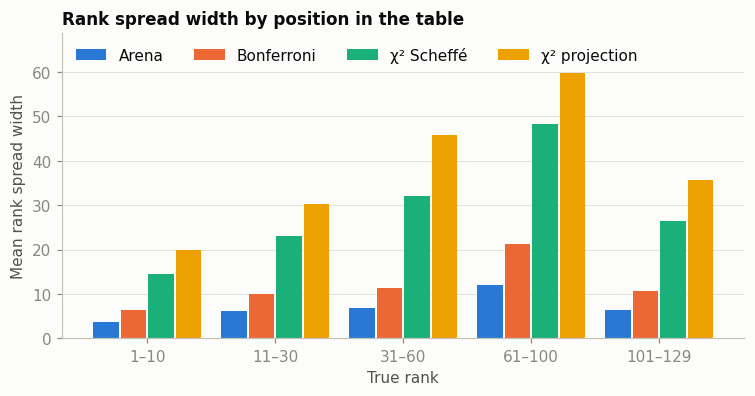

,Arena,Bonferroni,χ² Scheffé,χ² projection
True rank,,,,
1–10,3.7,6.4,14.5,19.8
11–30,6.1,9.9,23.0,30.3
31–60,6.8,11.3,32.1,45.8
61–100,12.1,21.2,48.3,59.8
101–129,6.4,10.7,26.4,35.6


In [3]:
tiers = pd.cut(per_model.true_rank, [0, 10, 30, 60, 100, M], labels=["1–10", "11–30", "31–60", "61–100", f"101–{M}"])
width = per_model.groupby(tiers, observed=True)[[f"{p}_mean_width" for p in PROCS]].mean()
width.columns = [name for name, _ in PROCS.values()]
width.index.name = "True rank"

fig, ax = plt.subplots(figsize=(8, 3.6))
x, bw = np.arange(len(width)), 0.2
for k, (name, color) in enumerate(PROCS.values()):
    ax.bar(x + (k - 1.5) * (bw + 0.015), width[name], width=bw, color=color, label=name, zorder=2)
ax.set_xticks(x, width.index)
ax.set_xlabel("True rank")
ax.set_ylabel("Mean rank spread width")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=4)
ax.set_ylim(0, width.values.max() * 1.15)
ax.set_title("Rank spread width by position in the table")
plt.show()

width.round(1)

The χ² versions widen every part of the table, and most of all the crowded middle: for true ranks 61–100, a rank spread averages 48 ranks under Scheffé and 60 under the projection. Near the top, where models are well separated, the absolute widths are smaller, but the top 10 still get rank spreads 2.3 (Scheffé) to 3.1 (projection) times as wide as Bonferroni's.

## 4. Result 3: how far from what is needed

The [Bonferroni notebook](q2_bonferroni.ipynb) found that a multiplier of about 2.1 would already make all rank spreads right 95% of the time. That point comes from the oracle sweep (it uses the true ranks), so it is a benchmark, not a usable method. The figure puts every procedure on the same two axes: what it costs (mean rank spread width) and what it delivers (the share of true orderings it declares). Here an ordering counts when the procedure itself declares "A above B". The table in Section 2 counts only orderings whose rank spreads do not overlap, which is stricter, so its percentages are lower.

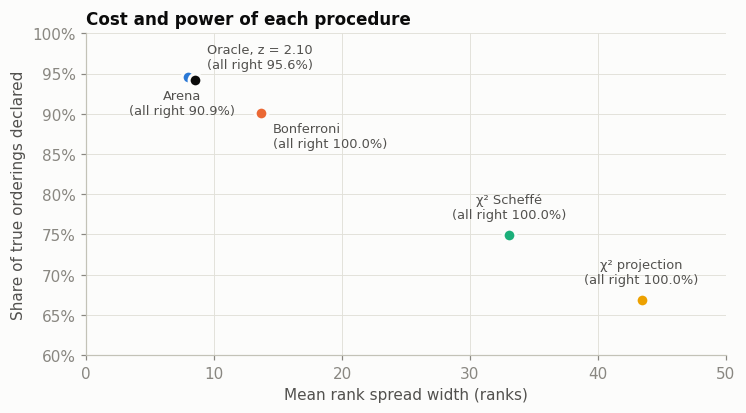

,Mean width,True orderings declared,All rank spreads right
Procedure,,,
Arena,7.99,94.5%,90.9%
"Oracle, z = 2.10",8.48,94.2%,95.6%
Bonferroni,13.65,90.1%,100.0%
χ² Scheffé,33.07,74.9%,100.0%
χ² projection,43.43,66.9%,100.0%


In [4]:
pts = [(name, color, summary.loc["rank interval width, mean", p],
        summary.loc["[declared orderings] power: share of true orderings declared", p],
        summary.loc["rank interval coverage, simultaneous (all models)", p]) for p, (name, color) in PROCS.items()]
enough = sweep.loc[sweep.z == Z_ENOUGH].iloc[0]
pts.insert(1, (f"Oracle, z = {Z_ENOUGH:.2f}", INK, enough.rs_width, enough.power, enough.rs_all_cover))

# label offsets (points) and alignment, set by hand so the three points near the top left don't collide
place = {"Arena": (-4, -8, "center", "top"), "Oracle": (8, 6, "left", "bottom"), "Bonferroni": (8, -6, "left", "top")}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, color, w, pw, cov in pts:
    ax.scatter([w], [pw], s=70, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
    dx, dy, ha, va = place.get(name.split(",")[0], (0, 9, "center", "bottom"))
    ax.annotate(f"{name}\n(all right {cov:.1%})", (w, pw), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, fontsize=8.5, color=INK2)
ax.set_xlim(0, 50)
ax.set_ylim(0.6, 1.0)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Mean rank spread width (ranks)")
ax.set_ylabel("Share of true orderings declared")
ax.set_title("Cost and power of each procedure")
plt.show()

pd.DataFrame([{"Procedure": n, "Mean width": round(w, 2), "True orderings declared": f"{pw:.1%}",
               "All rank spreads right": f"{cov:.1%}"} for n, _, w, pw, cov in pts]).set_index("Procedure")

- Arena sits just short of the target (90.9%). The oracle multiplier reaches it with almost no extra width (8.5 vs 8.0 ranks).
- Bonferroni pays about 5 extra ranks of width for the guarantee. Scheffé pays about 25, and the projection about 35.
- The χ² procedures are far outside the multiplier sweep: the largest multiplier on that grid ($z = 4$) gives a mean width of only 15.3.

**Why the χ² set is so expensive.** It guarantees that the entire score vector lies in an ellipsoid, which protects against errors in every direction of a 129-dimensional space at once. A ranking needs much less: it only depends on the signs of the pairwise differences. Bonferroni already guards against more than the ranking needs (Section 4 of the Bonferroni notebook), and the χ² set guards against far more.

## 5. Result 4: the real 2024 leaderboard

All four procedures applied to the real battles (the fit behind the 2024-08-12 leaderboard). The figure shows the top 20 models by score.

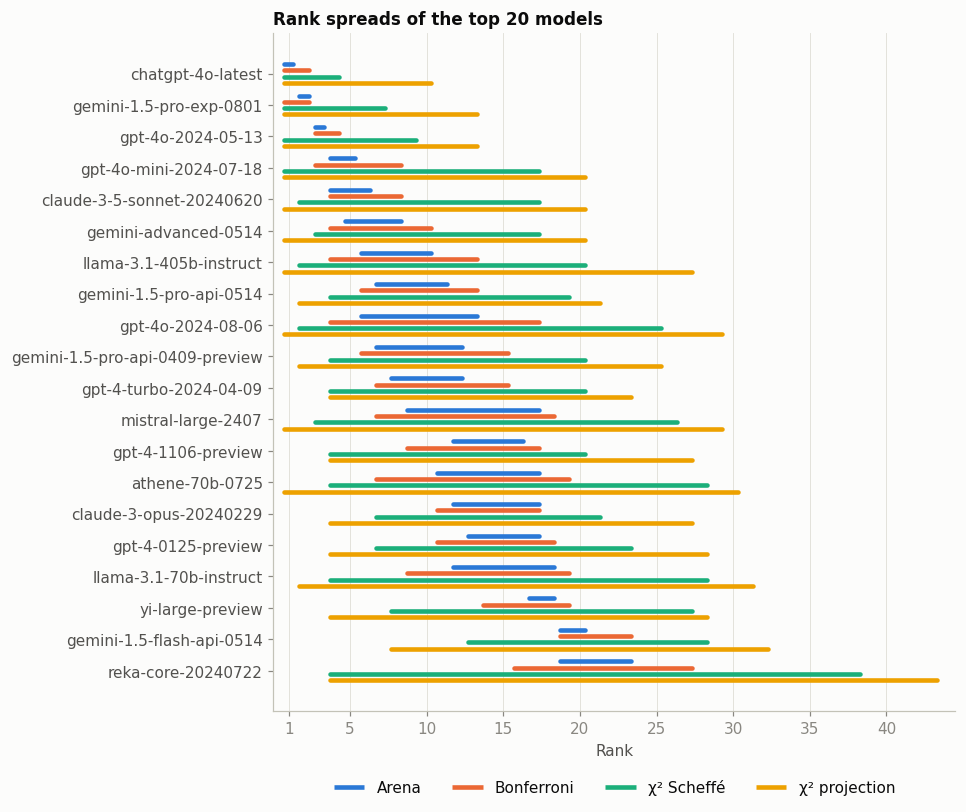

,Arena,Bonferroni,χ² Scheffé,χ² projection
Mean rank spread width,7.9,13.8,33.2,43.6
Widest rank spread,19,34,68,84
Models with a single rank (width 1),4,0,0,0
"Model pairs told apart (of 8,256)","7,808","7,430","6,179","5,509"
Rank spread of the top model,1–1,1–2,1–4,1–10


In [5]:
top = real.head(20).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(8, 8))
for off, (p, (name, color)) in zip([0.3, 0.1, -0.1, -0.3], PROCS.items()):
    ax.hlines(y + off, top[f"{p}_best"] - 0.3, top[f"{p}_worst"] + 0.3, color=color, lw=3, capstyle="round", label=name)
ax.set_yticks(y, top.model)
ax.tick_params(axis="y", labelcolor=INK2)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50])
ax.set_xlim(0, top.chi2_worst.max() + 1.5)
ax.set_xlabel("Rank")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4)
ax.set_title("Rank spreads of the top 20 models")
plt.show()

w = {p: real[f"{p}_worst"] - real[f"{p}_best"] + 1 for p in PROCS}
n_pairs = M * (M - 1) // 2
pd.DataFrame({
    "Mean rank spread width": {p: f"{w[p].mean():.1f}" for p in w},
    "Widest rank spread": {p: int(w[p].max()) for p in w},
    "Models with a single rank (width 1)": {p: int((w[p] == 1).sum()) for p in w},
    f"Model pairs told apart (of {n_pairs:,})": {p: f"{int(real[f'{p}_orderings'].sum()):,}" for p in w},
    "Rank spread of the top model": {p: f"{real[f'{p}_best'].iloc[0]}–{real[f'{p}_worst'].iloc[0]}" for p in w},
}).T.rename(columns={p: name for p, (name, _) in PROCS.items()})

- The top model (chatgpt-4o-latest) has a rank spread of 1–1 under Arena, 1–2 under Bonferroni, 1–4 under Scheffé and 1–10 under the projection.
- Under the projection, the widest rank spread covers 84 of the 129 ranks. A leaderboard like this tells a reader very little beyond the coarsest groups.

## Takeaways

1. **The χ² set is valid.** Both readings kept every rank spread right in all 1,000 simulated datasets, and neither produced a wrong ordering.
2. **It is the most expensive correction we tried.** Rank spreads are 2.4 (Scheffé) to 3.2 (projection) times as wide as Bonferroni's, and on the real leaderboard the top model's rank spread grows to 1–4 or 1–10.
3. **How the set is used matters.** Reading the set through pairwise differences (Scheffé) instead of projected intervals removes about a quarter of the width. This shows that the overlap rule and the ignored covariances have a real cost.
4. **Its guarantee is much stronger than a ranking needs.** In this simulation the procedures line up as oracle (z ≈ 2.1) < Bonferroni < χ² Scheffé < χ² projection, in both width and lost power. A procedure that targets the pairwise orderings directly, such as pairwise tests with Holm, should do better than any of the corrections tried so far.

**Limitations.** The χ² set relies on the normal approximation for the whole score vector, and its own 95% coverage was not checked directly here (only its projected intervals and the rank spreads). As in Q1 and the Bonferroni notebook, the simulation is a single idealized world (129 models with 2024 strengths, independent battles, exact Bradley–Terry). With today's roughly 400 models the χ² multiplier would grow to about 21.

## Reproduce

```bash
python q2.py --reps 1000 --procedures arena,bonferroni,chi2,chi2_scheffe,pairwise_bonferroni,holm_onesided,holm   # about 4 minutes; writes results/q2_*
pip install jupyter
jupyter nbconvert --to notebook --execute --inplace notebook/q2_chi2.ipynb
```